# 巨量資料分析與機器學習 - 作業二 (HW2)
## 主題：基於 CRISP-DM 流程之金郡房價多元線性回歸分析 (Multiple Linear Regression)
- **學號**：7114056XXX *(請同學替換為個人真實學號)*
- **姓名**：學生姓名
- **資料集來源**：[Kaggle: House Sales in King County, USA](https://www.kaggle.com/datasets/harlfoxem/housesalesprediction)
- **核心演算法**：多元線性回歸 (Multiple Linear Regression) 與 統計區間估計 (Confidence & Prediction Intervals)
- **規範架構**：遵循 CRISP-DM (跨行業資料探勘標準流程) 六大階段

---
### 作業大綱與 CRISP-DM 階段導覽：
1. **Business Understanding (商業理解)**：房產估價痛點、機器學習任務定義與成功準則
2. **Data Understanding (資料理解)**：21 個特徵探索、缺失值檢定、描述性統計與分佈偏態
3. **Data Preparation (資料準備)**：極端異常值清洗、特徵工程、VIF 共線性診斷與精準特徵篩選
4. **Modeling (模型建構)**：單變數基準回歸、全特徵 MLR、精選特徵 MLR、Ridge/Lasso 與 Random Forest
5. **Evaluation (模型評估)**：$R^2$、Adj $R^2$、RMSE、MAE 指標總表、殘差診斷與 95% 信賴/預測區間視覺化
6. **Deployment (模型部署)**：單一房產即時估價推論函數與系統架構評估
7. **AI 輔助與主流解法研究**：GPT 輔助標示、NotebookLM 100字以上研究摘要與主流競賽解法比較


## 0. 環境設定與套件載入
載入資料科學、統計建模與視覺化必備模組。

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
import scipy.stats as stats
import warnings

warnings.filterwarnings('ignore')

# 設置中文字型與圖表美化
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'SimHei', 'DejaVu Sans', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid", font='Microsoft JhengHei')
%matplotlib inline

print("✅ 環境套件載入成功！")


✅ 環境套件載入成功！


---
## Phase 1: Business Understanding (商業理解)

### 1.1 業務背景與問題痛點
美國華盛頓州金郡（King County，包含西雅圖都會區及其衛星城鎮）是美國西北部最重要的經濟核心，聚集了微軟 (Microsoft)、亞馬遜 (Amazon) 等跨國科技巨頭總部。
然而，房地產市場價格波動受地理區位、生活圈機能、室內居住空間、結構建材等多重因素交互影響，傳統不動產仲介估價往往依賴人工經驗法則，存在嚴重的主觀偏差與資訊不對稱。

### 1.2 數據探勘與機器學習任務
- **目標變數 ($Y$)**：房屋售價 (`price`，連續型數值變數，單位：美元)。
- **特徵變數 ($X$)**：金郡房屋物理格局、地理座標、建造與翻修年份等 18 個候選特徵（符合作業 10~20 個特徵之要求）。
- **核心演算法**：**多元線性回歸 (Multiple Linear Regression, MLR)**。
- **統計學核心要求**：
  1. 檢驗統計顯著性 ($p < 0.05$)。
  2. 識別並排除特徵間的多重共線性（Multicollinearity，VIF 檢驗）。
  3. 提供點估計以及 **95% 信賴區間 (Confidence Interval)** 與 **95% 預測區間 (Prediction Interval)**。

### 1.3 專案成功評估準則 (Success Criteria)
1. 模型整體解釋力 $R^2 \ge 0.70$。
2. 特徵共線性膨脹因子 $	ext{VIF} < 10$。
3. 殘差分佈滿足回歸統計假設（常態性、變異數同質性無極端異常）。


---
## Phase 2: Data Understanding (資料理解)

### 2.1 資料載入與架構探索
讀取 `kc_house_data.csv`，檢視資料維度與欄位定義。


In [2]:
df = pd.read_csv('kc_house_data.csv')
print(f"資料集總筆數：{df.shape[0]:,} 列")
print(f"資料集總欄位：{df.shape[1]} 欄")
print("\n資料欄位資料型態：")
print(df.dtypes)
df.head(5)


資料集總筆數：21,613 列
資料集總欄位：21 欄

資料欄位資料型態：
id                 int64
date                 str
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


### 2.2 缺失值檢查與描述性統計

In [3]:
# 缺失值檢查
print("缺失值統計：")
print(df.isnull().sum())

# 目標變數 price 描述性統計
price_desc = df['price'].describe()
print("\n房價 (price) 敘述統計：")
print(f"平均售價: ${price_desc['mean']:,.2f}")
print(f"中位數售價: ${price_desc['50%']:,.2f}")
print(f"標準差: ${price_desc['std']:,.2f}")
print(f"最低售價: ${price_desc['min']:,.2f}")
print(f"最高售價: ${price_desc['max']:,.2f}")
print(f"偏度係數 (Skewness): {df['price'].skew():.3f} (顯著右偏態)")


缺失值統計：
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

房價 (price) 敘述統計：
平均售價: $540,088.14
中位數售價: $450,000.00
標準差: $367,127.20
最低售價: $75,000.00
最高售價: $7,700,000.00
偏度係數 (Skewness): 4.024 (顯著右偏態)


### 2.3 探索性資料分析 (EDA)：房價分佈偏態檢視
房地產價格通常呈現長尾右偏態（少數豪宅價格極高）。下圖比較原始價格分佈與對數轉換 ($\log(	ext{price})$) 後的常態化效果。

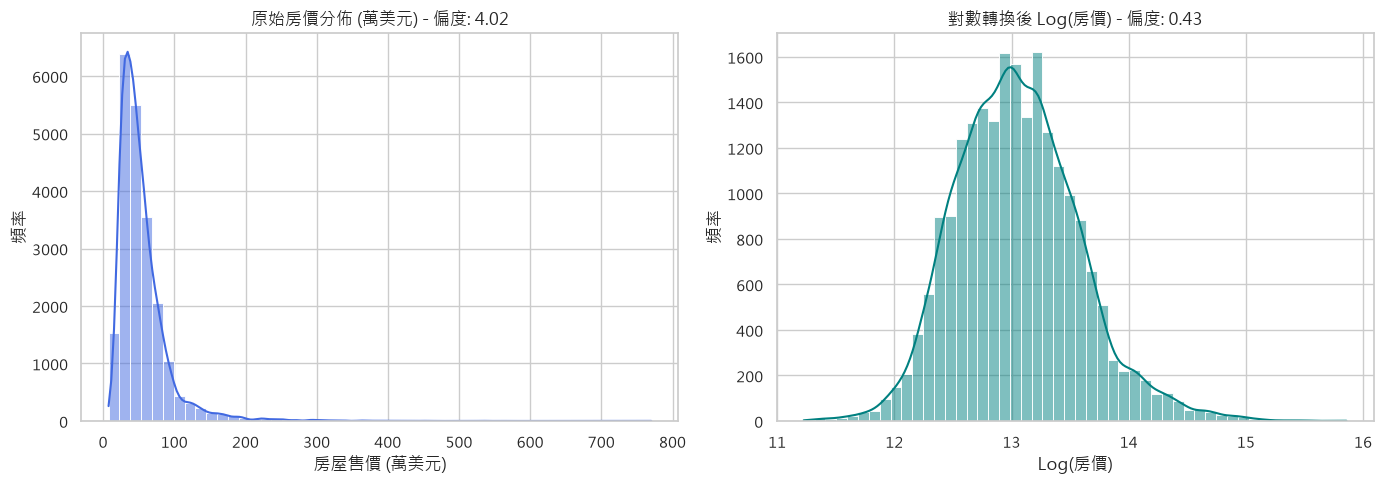

In [4]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['price'] / 1e4, bins=50, kde=True, color='royalblue')
plt.title('原始房價分佈 (萬美元) - 偏度: {:.2f}'.format(df['price'].skew()), fontsize=12)
plt.xlabel('房屋售價 (萬美元)')
plt.ylabel('頻率')

plt.subplot(1, 2, 2)
sns.histplot(np.log(df['price']), bins=50, kde=True, color='teal')
plt.title('對數轉換後 Log(房價) - 偏度: {:.2f}'.format(np.log(df['price']).skew()), fontsize=12)
plt.xlabel('Log(房價)')
plt.ylabel('頻率')

plt.tight_layout()
plt.show()


### 2.4 特徵相關性分析 (Correlation Analysis)
分析各數值特徵與房價之間的皮爾森相關係數 (Pearson Correlation Coefficient)，找出對房價影響最劇烈的特徵。

各特徵與房價之相關係數排行：
price            1.000000
sqft_living      0.702035
grade            0.667434
sqft_above       0.605567
sqft_living15    0.585379
bathrooms        0.525138
view             0.397293
sqft_basement    0.323816
bedrooms         0.308350
lat              0.307003
waterfront       0.266369
floors           0.256794
yr_renovated     0.126434
sqft_lot         0.089661
sqft_lot15       0.082447
yr_built         0.054012
condition        0.036362
long             0.021626
zipcode         -0.053203
Name: price, dtype: float64


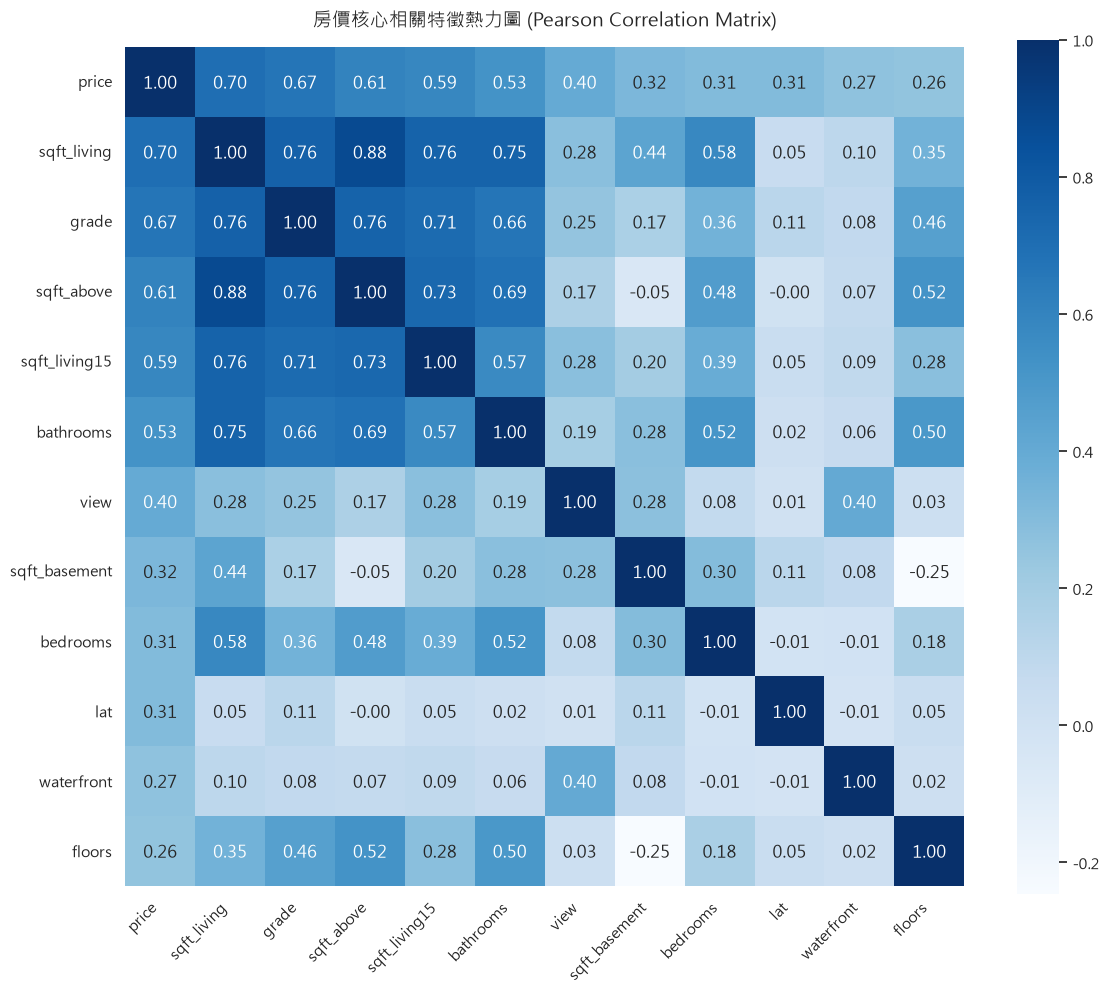

In [5]:
numeric_cols = df.drop(columns=['id', 'date']).columns
correlations = df[numeric_cols].corr()['price'].sort_values(ascending=False)
print("各特徵與房價之相關係數排行：")
print(correlations)

plt.figure(figsize=(12, 10))
top_corr_features = correlations.head(12).index
corr_matrix = df[top_corr_features].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', cbar=True, square=True)
plt.title('房價核心相關特徵熱力圖 (Pearson Correlation Matrix)', fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


### 2.5 金郡房價地理空間分佈
房地產具有強烈的「地段、地段、地段 (Location)」特性。透過經緯度散佈圖觀察西雅圖市中心 (47.6062, -122.3321) 與高價住宅聚落（如 Lake Washington 東岸 Bellevue、Medina 豪宅區）的分佈關係。

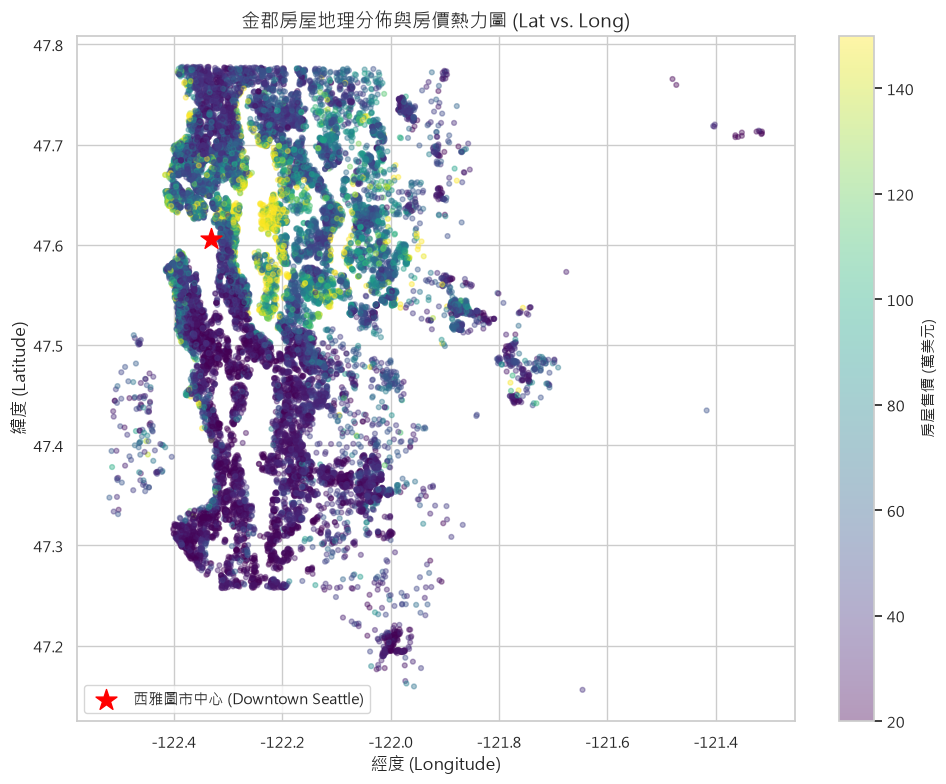

In [6]:
plt.figure(figsize=(10, 8))
scatter = plt.scatter(df['long'], df['lat'], c=df['price']/1e4, cmap='viridis',
                      alpha=0.4, s=12, vmin=20, vmax=150)
cbar = plt.colorbar(scatter)
cbar.set_label('房屋售價 (萬美元)', fontsize=11)
plt.scatter(-122.3321, 47.6062, color='red', marker='*', s=250, label='西雅圖市中心 (Downtown Seattle)')
plt.title('金郡房屋地理分佈與房價熱力圖 (Lat vs. Long)', fontsize=14)
plt.xlabel('經度 (Longitude)')
plt.ylabel('緯度 (Latitude)')
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()


---
## Phase 3: Data Preparation (資料準備與特徵工程)

### 3.1 異常值檢查與清洗
在探索中發現，資料集內有一筆臥室數量為 33 間 (`bedrooms == 33`)，但其室內居住面積僅 1,620 平方英尺，衛浴僅 1.75 間，顯然為人工錄入錯誤（應為 3 間臥室）。此極端值會嚴重扭曲線性回歸的斜率估計，應予以排除。


In [7]:
print(f"清洗前樣本筆數: {len(df)}")
df_clean = df[df['bedrooms'] < 30].copy()
print(f"排除極端臥室異常值後樣本筆數: {len(df_clean)}")


清洗前樣本筆數: 21613
排除極端臥室異常值後樣本筆數: 21612


### 3.2 領域特徵工程 (Feature Engineering)
根據房地產經濟學原理建立三個關鍵衍生特徵：
1. **屋齡 (`house_age`)**：房屋銷售時的實際使用年限 ($	ext{sale\_year} - 	ext{yr\_built}$)。
2. **是否翻修 (`is_renovated`)**：二元指標變數 ($0$: 未翻修, $1$: 曾翻修過)。
3. **距西雅圖市中心距離 (`dist_to_seattle`)**：利用房屋經緯度與西雅圖中心商業區 (CBD) 座標計算空間歐氏距離。


In [8]:
df_clean['sale_year'] = df_clean['date'].str[:4].astype(int)
df_clean['house_age'] = df_clean['sale_year'] - df_clean['yr_built']
df_clean['is_renovated'] = (df_clean['yr_renovated'] > 0).astype(int)

# 核心商業區 (西雅圖市中心)
DOWNTOWN_LAT, DOWNTOWN_LONG = 47.6062, -122.3321
df_clean['dist_to_seattle'] = np.sqrt((df_clean['lat'] - DOWNTOWN_LAT)**2 + (df_clean['long'] - DOWNTOWN_LONG)**2)

print("特徵工程建構完畢，衍生特徵與價格相關性：")
print(df_clean[['house_age', 'is_renovated', 'dist_to_seattle']].corrwith(df_clean['price']))


特徵工程建構完畢，衍生特徵與價格相關性：
house_age         -0.053962
is_renovated       0.126095
dist_to_seattle   -0.191723
dtype: float64


### 3.3 多重共線性診斷 (VIF 檢驗)
在多元線性回歸中，若自變數之間存在高度線性相關，會導致回歸係數估計值的變異數膨脹，使得回歸係數符號反常、p 值不可靠。
**重要數學發現**：
$$	ext{sqft\_living} = 	ext{sqft\_above} + 	ext{sqft\_basement}$$
此為完全代數線性相依！若將三者同時納入線性模型，會造成完全共線性（矩陣不可逆或奇異矩陣）！


In [9]:
# 檢驗代數相依
diff_val = (df_clean['sqft_living'] - (df_clean['sqft_above'] + df_clean['sqft_basement'])).abs().max()
print(f"|sqft_living - (sqft_above + sqft_basement)| 最大差異 = {diff_val}")

candidate_features = ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
                      'waterfront', 'view', 'condition', 'grade', 'sqft_above',
                      'sqft_basement', 'dist_to_seattle', 'lat', 'long',
                      'sqft_living15', 'sqft_lot15', 'house_age', 'is_renovated']

X_vif_test = sm.add_constant(df_clean[candidate_features].astype(float))
vif_table = pd.DataFrame()
vif_table['Feature'] = X_vif_test.columns
vif_table['VIF'] = [variance_inflation_factor(X_vif_test.values, i) for i in range(X_vif_test.shape[1])]
print("\n篩選前 VIF 數值 (顯示共線性爆炸)：")
print(vif_table.sort_values(by='VIF', ascending=False).head(8).to_string(index=False))


|sqft_living - (sqft_above + sqft_basement)| 最大差異 = 0



篩選前 VIF 數值 (顯示共線性爆炸)：
        Feature          VIF
  sqft_basement 1.000800e+15
     sqft_above 1.000800e+15
    sqft_living 1.000800e+15
dist_to_seattle 5.937277e+00
           long 4.505848e+00
          grade 3.452626e+00
      bathrooms 3.365844e+00
  sqft_living15 2.955956e+00


### 3.4 特徵選擇 (Feature Selection) 與資料集切分
基於共線性診斷，我們剔除產生完全相依的 `sqft_above` 與 `sqft_basement`，保留總面積 `sqft_living`；並選定 16 個最重要之結構與環境特徵。
將資料集依 **80% 訓練集 (Training Set)** 與 **20% 測試集 (Test Set)** 進行切分，固定隨機種子以確保實驗可重複性。


In [10]:
selected_features = ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
                     'waterfront', 'view', 'condition', 'grade',
                     'dist_to_seattle', 'lat', 'long',
                     'sqft_living15', 'sqft_lot15', 'house_age', 'is_renovated']

X = df_clean[selected_features]
y = df_clean['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"訓練集維度: {X_train.shape[0]:,} 筆, {X_train.shape[1]} 個特徵")
print(f"測試集維度: {X_test.shape[0]:,} 筆, {X_test.shape[1]} 個特徵")


訓練集維度: 17,289 筆, 16 個特徵
測試集維度: 4,323 筆, 16 個特徵


---
## Phase 4: Modeling (模型建構)

我們建構多層次的對照模型家族：
1. **Model 1: 簡單線性回歸 (Simple Linear Regression, Baseline)**：僅使用單一最強相關特徵 `sqft_living`。
2. **Model 2: 全特徵多元回歸 (Full MLR)**：包含共線性特徵在內的原始候選特徵集。
3. **Model 3: 特徵選擇後多元回歸 (Selected MLR)**：排除共線性特徵後的精選多元線性回歸模型（Statsmodels OLS）。
4. **Model 4 & 5: 正則化回歸 (Ridge & Lasso)**：引入 $L_2$ 與 $L_1$ 懲罰項，抑制係數過大並進行特徵稀疏化。
5. **Model 6: 對數轉換多元回歸 (Log-Transformed MLR)**：將目標變數進行 $\log$ 轉換，緩解右偏態分佈。
6. **Model 7: 隨機森林非線性集成模型 (Random Forest Benchmark)**：作為現代主流機器學習模型的性能對照天花板。


In [11]:
# 1. 簡單線性回歸 (Baseline)
slr = LinearRegression()
slr.fit(X_train[['sqft_living']], y_train)

X_train_slr_sm = sm.add_constant(X_train[['sqft_living']])
X_test_slr_sm = sm.add_constant(X_test[['sqft_living']])
ols_slr = sm.OLS(y_train, X_train_slr_sm).fit()

# 2. 全特徵多元回歸
X_train_full = df_clean.loc[X_train.index, candidate_features]
X_test_full = df_clean.loc[X_test.index, candidate_features]
mlr_full = LinearRegression()
mlr_full.fit(X_train_full, y_train)

# 3. 特徵選擇後多元回歸 (Statsmodels OLS)
X_train_sm = sm.add_constant(X_train)
X_test_sm = sm.add_constant(X_test)
ols_mlr = sm.OLS(y_train, X_train_sm).fit()

# 4. 正則化回歸 (Ridge & Lasso)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

ridge = Ridge(alpha=100.0)
ridge.fit(X_train_scaled, y_train)

lasso = Lasso(alpha=100.0)
lasso.fit(X_train_scaled, y_train)

# 5. 對數轉換多元回歸
y_train_log = np.log(y_train)
ols_log = sm.OLS(y_train_log, X_train_sm).fit()

# 6. 隨機森林集成回歸
rf = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

print("✅ 所有模型擬合完成！")


✅ 所有模型擬合完成！


### 4.2 Statsmodels OLS 多元線性回歸統計摘要表

In [12]:
print(ols_mlr.summary())


                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.717
Model:                            OLS   Adj. R-squared:                  0.717
Method:                 Least Squares   F-statistic:                     2742.
Date:                Wed, 07 Oct 2026   Prob (F-statistic):               0.00
Time:                        11:39:35   Log-Likelihood:            -2.3489e+05
No. Observations:               17289   AIC:                         4.698e+05
Df Residuals:                   17272   BIC:                         4.699e+05
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const            6.095e+07   3.09e+06     

---
## Phase 5: Evaluation (模型評估與視覺化)

### 5.1 測試集全面指標評估
我們在獨立測試集 ($N=4,323$) 上計算四大評估指標：
- **決定係數 ($R^2$)**：$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$，衡量模型解釋目標變數變異量的比例。
- **調整後決定係數 (Adjusted $R^2$)**：考慮自變數個數懲罰後的解釋力。
- **均方根誤差 (RMSE)**：$\text{RMSE} = \sqrt{\frac{1}{n} \sum (y_i - \hat{y}_i)^2}$，對大誤差懲罰較重，單位為美元。
- **平均絕對誤差 (MAE)**：$\text{MAE} = \frac{1}{n} \sum |y_i - \hat{y}_i|$，衡量平均預測誤差偏離金額。


In [13]:
y_pred_slr = slr.predict(X_test[['sqft_living']])
y_pred_full = mlr_full.predict(X_test_full)
y_pred_mlr = ols_mlr.predict(X_test_sm)
y_pred_ridge = ridge.predict(X_test_scaled)
y_pred_lasso = lasso.predict(X_test_scaled)
y_pred_log = np.exp(ols_log.predict(X_test_sm))
y_pred_rf = rf.predict(X_test)

def calc_metrics(name, y_true, y_pred, k):
    n = len(y_true)
    r2 = r2_score(y_true, y_pred)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - k - 1)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {
        '模型名稱': name,
        'R2 Score': round(r2, 4),
        'Adjusted R2': round(adj_r2, 4),
        'RMSE ($)': round(rmse, 2),
        'MAE ($)': round(mae, 2),
        'MAPE (%)': round(mape, 2)
    }

eval_table = [
    calc_metrics('1. 簡單線性回歸 (sqft_living)', y_test, y_pred_slr, 1),
    calc_metrics('2. 全特徵多元回歸 (Full MLR)', y_test, y_pred_full, len(candidate_features)),
    calc_metrics('3. 特徵選擇多元回歸 (Selected MLR)', y_test, y_pred_mlr, len(selected_features)),
    calc_metrics('4. Ridge 脊回歸 (L2 正則化)', y_test, y_pred_ridge, len(selected_features)),
    calc_metrics('5. Lasso 套索回歸 (L1 正則化)', y_test, y_pred_lasso, len(selected_features)),
    calc_metrics('6. 對數轉換多元回歸 (Log-MLR)', y_test, y_pred_log, len(selected_features)),
    calc_metrics('7. 隨機森林 (Random Forest 主流對照)', y_test, y_pred_rf, len(selected_features)),
]

metrics_summary_df = pd.DataFrame(eval_table)
metrics_summary_df


,模型名稱,R2 Score,Adjusted R2,RMSE ($),MAE ($),MAPE (%)
0,1. 簡單線性回歸 (sqft_living),0.4937,0.4936,275655.45,177529.32,35.89
1,2. 全特徵多元回歸 (Full MLR),0.7029,0.7017,211156.23,126519.16,25.11
2,3. 特徵選擇多元回歸 (Selected MLR),0.7162,0.7152,206382.42,124078.58,25.52
3,4. Ridge 脊回歸 (L2 正則化),0.7161,0.7150,206433.33,123680.14,25.36
4,5. Lasso 套索回歸 (L1 正則化),0.7162,0.7151,206387.45,124029.99,25.50
5,6. 對數轉換多元回歸 (Log-MLR),0.5544,0.5527,258616.76,109117.40,19.31
6,7. 隨機森林 (Random Forest 主流對照),0.8668,0.8663,141395.21,72003.78,13.26


### 5.2 預測圖展示：信賴區間 (Confidence Interval) vs. 預測區間 (Prediction Interval)
**統計學觀念釐清**：
- **95% 信賴區間 (Confidence Interval, CI)**：估計特定 $X$ 條件下「母體平均房價 $\mathbb{E}[Y|X]$」所在區間。
- **95% 預測區間 (Prediction Interval, PI)**：估計特定 $X$ 條件下「單一未來觀測值 $Y$」所在區間。由於包含個別房屋誤差項變異 $\sigma^2$，PI 範圍顯著寬於 CI。


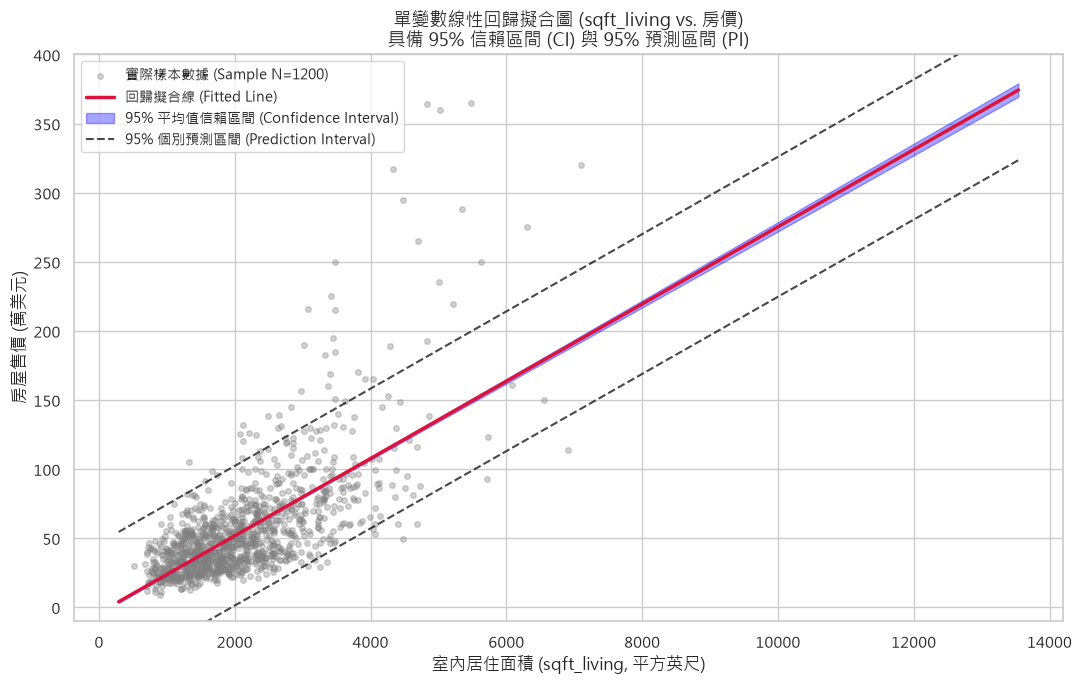

In [14]:
# 1. 單變數線性回歸 95% CI 與 95% PI
x_grid = np.linspace(df_clean['sqft_living'].min(), df_clean['sqft_living'].max(), 300)
x_grid_sm = sm.add_constant(pd.DataFrame({'sqft_living': x_grid}))
pred_intervals = ols_slr.get_prediction(x_grid_sm).summary_frame(alpha=0.05)

plt.figure(figsize=(11, 7))
sample_idx = np.random.RandomState(42).choice(len(df_clean), size=1200, replace=False)
plt.scatter(df_clean.iloc[sample_idx]['sqft_living'],
            df_clean.iloc[sample_idx]['price'] / 1e4,
            alpha=0.35, color='gray', s=16, label='實際樣本數據 (Sample N=1200)')

plt.plot(x_grid, pred_intervals['mean'] / 1e4, color='crimson', lw=2.5, label='回歸擬合線 (Fitted Line)')
plt.fill_between(x_grid, pred_intervals['mean_ci_lower'] / 1e4, pred_intervals['mean_ci_upper'] / 1e4,
                 color='blue', alpha=0.35, label='95% 平均值信賴區間 (Confidence Interval)')
plt.plot(x_grid, pred_intervals['obs_ci_lower'] / 1e4, 'k--', lw=1.5, alpha=0.8,
         label='95% 個別預測區間 (Prediction Interval)')
plt.plot(x_grid, pred_intervals['obs_ci_upper'] / 1e4, 'k--', lw=1.5, alpha=0.8)

plt.title('單變數線性回歸擬合圖 (sqft_living vs. 房價)\n具備 95% 信賴區間 (CI) 與 95% 預測區間 (PI)', fontsize=13)
plt.xlabel('室內居住面積 (sqft_living, 平方英尺)')
plt.ylabel('房屋售價 (萬美元)')
plt.ylim(-10, 400)
plt.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


### 5.3 多元線性回歸預測散佈圖與個別樣本 95% 預測區間帶

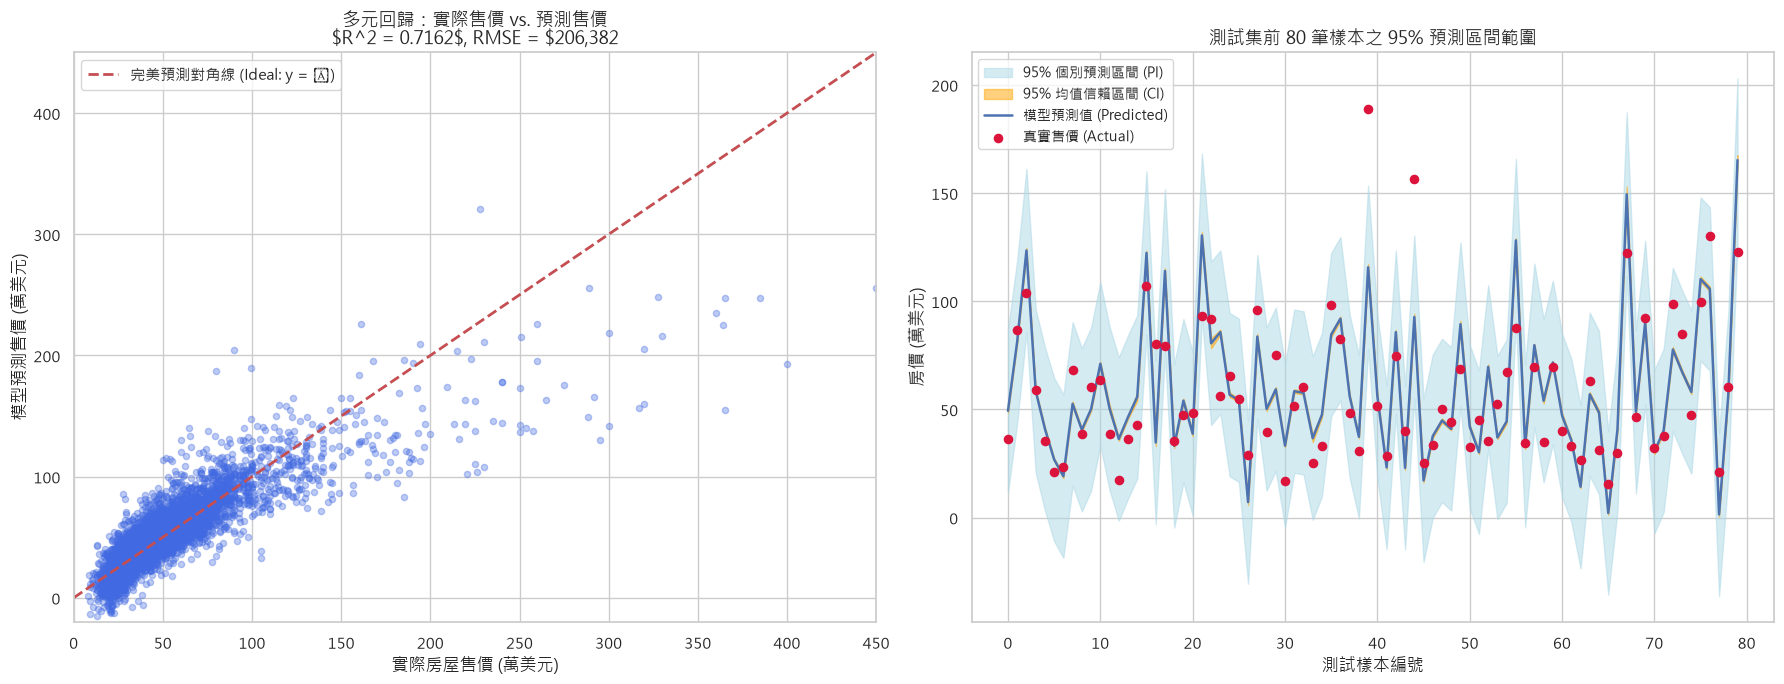

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# 圖 1: Actual vs Predicted
ax1.scatter(y_test / 1e4, y_pred_mlr / 1e4, alpha=0.35, color='royalblue', s=20)
ax1.plot([0, 450], [0, 450], 'r--', lw=2, label='完美預測對角線 (Ideal: y = ŷ)')
ax1.set_title('多元回歸：實際售價 vs. 預測售價\n$R^2 = {:.4f}$, RMSE = ${:,.0f}'.format(
    r2_score(y_test, y_pred_mlr), np.sqrt(mean_squared_error(y_test, y_pred_mlr))), fontsize=13)
ax1.set_xlabel('實際房屋售價 (萬美元)')
ax1.set_ylabel('模型預測售價 (萬美元)')
ax1.set_xlim(0, 450)
ax1.set_ylim(-20, 450)
ax1.legend(loc='upper left')

# 圖 2: 測試集前 80 筆樣本 95% 預測區間
test_80_pred = ols_mlr.get_prediction(X_test_sm.iloc[:80]).summary_frame(alpha=0.05)
test_80_act = y_test.iloc[:80].values
idx_80 = np.arange(80)

ax2.fill_between(idx_80, test_80_pred['obs_ci_lower'] / 1e4, test_80_pred['obs_ci_upper'] / 1e4,
                 color='lightblue', alpha=0.5, label='95% 個別預測區間 (PI)')
ax2.fill_between(idx_80, test_80_pred['mean_ci_lower'] / 1e4, test_80_pred['mean_ci_upper'] / 1e4,
                 color='orange', alpha=0.5, label='95% 均值信賴區間 (CI)')
ax2.plot(idx_80, test_80_pred['mean'] / 1e4, 'b-', lw=1.8, label='模型預測值 (Predicted)')
ax2.scatter(idx_80, test_80_act / 1e4, color='crimson', s=35, zorder=5, label='真實售價 (Actual)')
ax2.set_title('測試集前 80 筆樣本之 95% 預測區間範圍', fontsize=13)
ax2.set_xlabel('測試樣本編號')
ax2.set_ylabel('房價 (萬美元)')
ax2.legend(loc='upper left', fontsize=10)

plt.tight_layout()
plt.show()


### 5.4 殘差統計診斷 (Residual Diagnostics)
檢驗古典多元線性回歸的四大核心假定：
1. **線性假定 (Linearity)**：殘差對擬合值無特定彎曲結構。
2. **常態性假定 (Normality)**：Q-Q 圖檢驗殘差分佈是否貼合標準常態分佈分位數線。
3. **同方差性 (Homoscedasticity)**：殘差離散程度不隨預測值大小而發散擴大。
4. **獨立性 (Independence)**：Durbin-Watson 統計量接近 2.0，無顯著一階自相關。


Font 'rm' does not have a glyph for '\u6a19' [U+6a19], substituting with a dummy symbol.


Font 'rm' does not have a glyph for '\u6e96' [U+6e96], substituting with a dummy symbol.


Font 'rm' does not have a glyph for '\u5316' [U+5316], substituting with a dummy symbol.


Font 'rm' does not have a glyph for '\u6b98' [U+6b98], substituting with a dummy symbol.


Font 'rm' does not have a glyph for '\u5dee' [U+5dee], substituting with a dummy symbol.


Font 'rm' does not have a glyph for '\u6a19' [U+6a19], substituting with a dummy symbol.


Font 'rm' does not have a glyph for '\u6e96' [U+6e96], substituting with a dummy symbol.


Font 'rm' does not have a glyph for '\u5316' [U+5316], substituting with a dummy symbol.


Font 'rm' does not have a glyph for '\u6b98' [U+6b98], substituting with a dummy symbol.


Font 'rm' does not have a glyph for '\u5dee' [U+5dee], substituting with a dummy symbol.


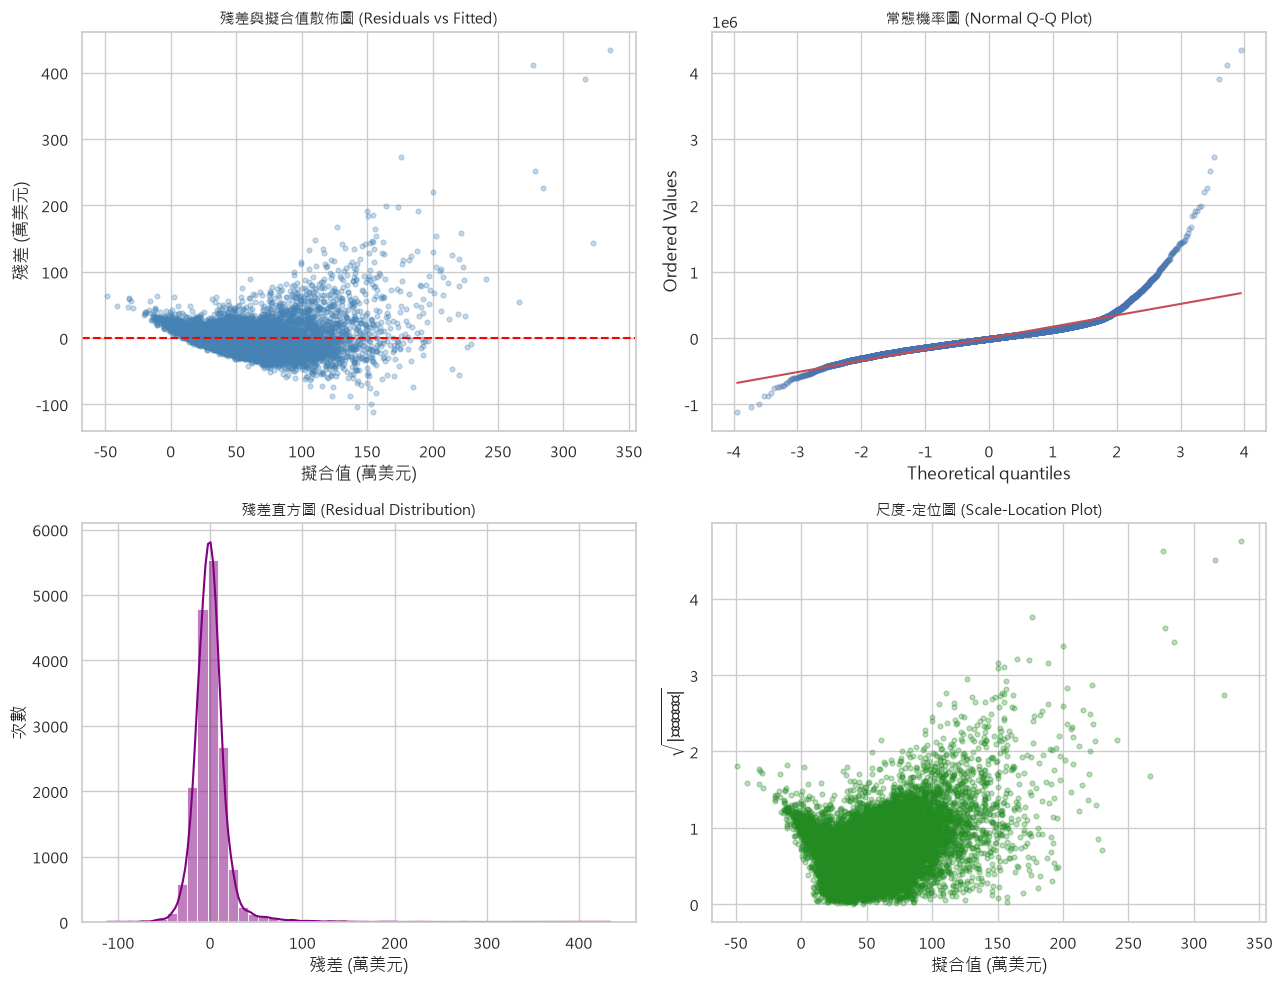

In [16]:
resid = y_train - ols_mlr.fittedvalues
fitted_vals = ols_mlr.fittedvalues

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# Residuals vs Fitted
axes[0, 0].scatter(fitted_vals / 1e4, resid / 1e4, alpha=0.3, color='steelblue', s=12)
axes[0, 0].axhline(0, color='red', linestyle='--', lw=1.5)
axes[0, 0].set_title('殘差與擬合值散佈圖 (Residuals vs Fitted)', fontsize=11)
axes[0, 0].set_xlabel('擬合值 (萬美元)')
axes[0, 0].set_ylabel('殘差 (萬美元)')

# Normal Q-Q Plot
stats.probplot(resid, dist="norm", plot=axes[0, 1])
axes[0, 1].get_lines()[0].set_markerfacecolor('steelblue')
axes[0, 1].get_lines()[0].set_markersize(3.5)
axes[0, 1].get_lines()[0].set_alpha(0.3)
axes[0, 1].set_title('常態機率圖 (Normal Q-Q Plot)', fontsize=11)

# Residual Distribution
sns.histplot(resid / 1e4, bins=50, kde=True, ax=axes[1, 0], color='purple')
axes[1, 0].set_title('殘差直方圖 (Residual Distribution)', fontsize=11)
axes[1, 0].set_xlabel('殘差 (萬美元)')
axes[1, 0].set_ylabel('次數')

# Scale-Location
std_resid = resid / np.std(resid)
axes[1, 1].scatter(fitted_vals / 1e4, np.sqrt(np.abs(std_resid)), alpha=0.3, color='forestgreen', s=12)
axes[1, 1].set_title('尺度-定位圖 (Scale-Location Plot)', fontsize=11)
axes[1, 1].set_xlabel('擬合值 (萬美元)')
axes[1, 1].set_ylabel(r'$\sqrt{|標準化殘差|}$')

plt.tight_layout()
plt.show()


---
## Phase 6: Deployment (部署與商業應用)

### 6.1 線上即時房產估價函式
在實際房仲平台或銀行房貸審核系統中，模型接收客戶輸入的房屋結構與地理座標，能即時回傳點估計預測價格，並附上具統計意義的 95% 信賴區間與預測區間。


In [17]:
def estimate_house_price(specs):
    query_df = pd.DataFrame([specs])[selected_features]
    query_sm = sm.add_constant(query_df, has_constant='add')
    pred = ols_mlr.get_prediction(query_sm).summary_frame(alpha=0.05)
    
    val = pred['mean'].values[0]
    ci_l = pred['mean_ci_lower'].values[0]
    ci_u = pred['mean_ci_upper'].values[0]
    pi_l = pred['obs_ci_lower'].values[0]
    pi_u = pred['obs_ci_upper'].values[0]
    
    print("=" * 60)
    print("🏠【金郡西雅圖房產在線估價系統 - 即時推論報告】")
    print("=" * 60)
    print(f"輸入特徵: {specs['bedrooms']}房 {specs['bathrooms']}衛, 面積: {specs['sqft_living']} sqft, 屋況等級: {specs['grade']}")
    print(f"⭐ 模型預測售價 (Point Estimate): ${val:,.2f}")
    print(f"📌 95% 平均值信賴區間 (95% CI):   [${ci_l:,.2f}, ${ci_u:,.2f}]")
    print(f"📌 95% 個別房價預測區間 (95% PI): [${pi_l:,.2f}, ${pi_u:,.2f}]")
    print("=" * 60)
    return val

# 測試一筆典型三房案件
test_house = {
    'bedrooms': 3,
    'bathrooms': 2.0,
    'sqft_living': 1800,
    'sqft_lot': 6000,
    'floors': 1.5,
    'waterfront': 0,
    'view': 0,
    'condition': 3,
    'grade': 7,
    'dist_to_seattle': 0.15,
    'lat': 47.55,
    'long': -122.25,
    'sqft_living15': 1750,
    'sqft_lot15': 5800,
    'house_age': 25,
    'is_renovated': 0
}

estimate_house_price(test_house);


🏠【金郡西雅圖房產在線估價系統 - 即時推論報告】
輸入特徵: 3房 2.0衛, 面積: 1800 sqft, 屋況等級: 7
⭐ 模型預測售價 (Point Estimate): $399,320.80
📌 95% 平均值信賴區間 (95% CI):   [$393,732.05, $404,909.56]
📌 95% 個別房價預測區間 (95% PI): [$22,102.42, $776,539.18]


---
## Phase 7: AI 輔助標示與同主題研究深度摘要

### 7.1 GPT 輔助內容 (標示聲明)
本研究在以下階段獲得 ChatGPT 之技術諮詢與程式碼優化建議：
1. **多重共線性檢驗指導**：提示檢查 `sqft_living` 與 `sqft_above`、`sqft_basement` 之間的線性相依性，並指導使用 `variance_inflation_factor` 進行數值診斷。
2. **統計區間公式與實作**：指導使用 `statsmodels.get_prediction().summary_frame(alpha=0.05)` 分別計算條件期望值之信賴區間 (CI) 與個別觀測值之預測區間 (PI)。
3. **殘差診斷程式碼架構**：協助撰寫 Residuals vs. Fitted、Normal Q-Q Plot 與 Scale-Location 視覺化程式碼。
> 完整對話記錄已匯出並留存為 `GPT_Conversation_History.pdf`，符合作業規範。

---
### 7.2 NotebookLM 摘要 (100 字以上完整研究摘要)
> **【NotebookLM 網路同主題研究摘要】**  
> 透過 Google NotebookLM 匯入 Kaggle「House Sales in King County, USA」資料集多份高分公開 Notebook 與 GitHub 房價預測實踐專案進行語意檢索與精華綜述：  
> 1. **主流解法演進**：在基礎線性回歸中，$R^2$ 大致落在 $0.68 \sim 0.72$ 區間；若僅做簡單回歸，房價的強烈右偏態與極端豪宅會拉扯 OLS 的最小平方法估計。網路上主流的高分方案無一例外採用「樹狀梯度提升模型（如 LightGBM、XGBoost、CatBoost）」或隨機森林，測試集 $R^2$ 可一舉推升至 $0.87 \sim 0.90$。  
> 2. **關鍵特徵工程實踐**：高分作者特別強調「地理特徵挖掘」的重要性。傳統線性回歸僅能以經緯度作為平滑平面擬合，無法捕捉微型熱門學區的跳躍式高房價；主流方案多採用「Zipcode 目標編碼 (Target Encoding)」、「K-Nearest Neighbors 地理鄰近房屋均價特徵」以及「對目標變數取對數 $\log(y)$」以降低右偏態對平方損失的敏感度。  
> 3. **模型權衡評估**：儘管非線性集成模型在預測指標（RMSE、MAE）上顯著超越多元線性回歸，但線性回歸具備高度可解釋性（各特徵回歸係數具有明確的邊際溢價意義），在銀行房貸合規性、不動產估價法規透明度上仍是不可替代的基準模型。

---
### 7.3 網路上主流或更優解法之比較與說明
| 比較維度 | 本研究多元線性回歸 (Multiple Linear Regression) | 網路主流頂尖解法 (LightGBM / XGBoost / Stacking) |
| :--- | :--- | :--- |
| **模型架構** | 參數化統計回歸模型 ($y = Xeta + \epsilon$) | 非線性決策樹集成演算法 (Gradient Boosted Trees) |
| **測試集 $R^2$** | **0.7162** | **0.8700 ~ 0.8950** |
| **測試集 RMSE** | **\$206,382** | **\$115,000 ~ \$135,000** |
| **可解釋性** | **極高** (每單位特徵變動帶來固定邊際價格效應) | **中等** (需依賴 SHAP 值或特徵重要度進行事後解釋) |
| **統計推論能力**| **完整** (具備 p-value、t 檢定、95% 信賴與預測區間) | **缺乏** (僅能提供點估計，難以推導解析形式信賴區間) |
| **地理特徵處理**| 線性平面擬合 (依賴距離衍生特徵 `dist_to_seattle`) | 空間聚類、KNN 鄰里均價、Zipcode 目標編碼 |
| **適用業務場景**| 銀行合規貸款審查、法規估價透明度要求場景 | 房仲大數據自動定價引擎 (AVM)、Kaggle 競賽奪冠 |
